# Part J — Fits on 13 points and the TOD prediction at any frequency (RHINO)

**Origin:** `notebooks/19_power_law_tod_prediction.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/19_power_law_tod_prediction.ipynb`)

| | |
|---|---|
| **Reads** | `res/`, `configs/run_pipeline.yaml`, `configs/model_comp_config.yaml`, `error_bars.csv`, `external/irfan_puglisi_2025/` (third party) |
| **Writes** | `test_outputs/tod_prediction/` (Tests 1–5; Test 6's last outputs of 2026-11-05 are kept there) |
| **Feeds the paper** | nothing: the RHINO prediction (fig10, Section 7) is pipeline step 7 |

**Stored outputs** are from the original notebook (not re-run after the merge). **Survey set: 13 points** (six + LWA1 38, 40, 45, 50, 60, 70, 74 MHz). Its first cell's "4 survey points … and both TRIS frequencies" is out of date.

**Pipeline:** Test 6 (RHINO) is pipeline step 7, fed by our spectral model (step 5) rather than this Part's 13-point weighted-least-squares fit.

## Power-law and curved power-law fits along the TRIS ring, and TOD prediction at any frequency

**What.** A spectral model is fitted at each of the 120 TRIS ring samples (TOD route, everything seen through the TRIS
beam), using the **4 survey points of the model comparison and both TRIS frequencies**. The fitted model then
**predicts the ring TOD at any frequency**, still through the TRIS beam. The whole analysis is done for each model in
`FIT_MODELS` (settings): the **power law** (the comparison's winner) and the **curved power law** (a close second),
shown side by side in every test.

* **Data, per ring sample:** the data sets in `DATASETS` (settings), currently 13 points: TRIS 600 and 820 MHz ring
  data (effective 600.5 / 817.8 MHz), and the beam-matched ring TODs (`sed.tod_beam: beam_matched`) of the nine LWA1
  maps (35, 38, 40, 45, 50, 60, 70, 74, 80 MHz; Dowell et al. 2017), Maipu 45 and Stockert 1420 MHz.
  **Caveat:** the nine LWA1 maps share one calibration, but each point carries its own 20% scale error, treated as
  independent of the others; together they therefore pull the fit harder than one 20%-calibrated survey should.
  Haslam 408 MHz is **not** fitted: it is the target, and is used here only as a held-out check (Test 4).
* **Points and error bars** are built by the model comparison's own code (`run_comparison.select_datasets` and
  `tod_units`), so they are exactly the points `run_comparison.py` would fit with these data sets. Error bars are the
  published ones (`configs/error_bars.csv`; TRIS: `sed_prototype.ring_sigma`).
* **Temperatures** are Rayleigh-Jeans with the CMB removed (the fit convention). `predict_tod(..., include_cmb=True)`
  adds T_CMB,RJ(ν) back for a TOD in the convention of the TRIS ring data.
* **Models**, with x = ln(ν/ν0), ν0 = 408 MHz (`configs/model_comp_config.yaml`), as in `model_comparison/models.py`:
  power law T = A exp(β x) (2 parameters); curved power law T = A exp(β x + C x²) (3 parameters).
  dof = number of points − number of parameters.
* **Fit:** weighted least squares, i.e. the minimum of χ² = Σ ((T_i − model_i)/σ_i)², the maximum of the Gaussian
  likelihood. No priors, no Occam penalty. Parameter covariance from the published errors only (`absolute_sigma=True`),
  **not** rescaled by χ²/dof.
* **Prediction uncertainty:** 1σ from the full parameter covariance, σ_T² = J C Jᵀ, so the parameter correlations are
  kept. Outside 35–1420 MHz the prediction is an extrapolation, and there the two models part ways fastest.
* **Residuals** are always data − model in K, with the data's ±1σ shaded beside them.
* **Test 6** takes the best-fit prediction to RHINO (60–80 MHz): deconvolved from the TRIS beam, observed with
  the RHINO beam, against GSM2008, GSM2016 and LFSM through the same beams.

**Outputs** go to `paper_outputs/tod_prediction/` (plots, CSVs; file names carry the model, e.g. `_power_law`, `_curved_power_law`;
the input cache in `paper_outputs/tod_prediction/cache/` is git-ignored). Nothing outside that folder is written, and no existing
code is changed. The whole notebook runs in well under a minute once the cache exists.

### Settings

In [ ]:
%matplotlib inline
import time as _nb_time; _NB_T0 = _nb_time.time()   # notebook run time, printed by the last cell
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "run_pipeline.yaml").exists())
MC_DIR = REPO / "scripts" / "model_comparison"
OUT_DIR = REPO / "test_outputs" / "tod_prediction"   # a check: the RHINO prediction is pipeline step 7
CACHE_DIR = OUT_DIR / "cache"
OUT_DIR.mkdir(exist_ok=True); CACHE_DIR.mkdir(exist_ok=True)
ERRORS_CSV = REPO / "configs" / "error_bars.csv"

# ---- the spectral models to fit (names as in model_comparison/models.py); every test shows each of them ----
FIT_MODELS = ["power law", "curved power law"]

# ---- the data sets in every fit (keys as in error_bars.csv); Haslam is never a fit point ----
DATASETS = ["TRIS_600", "TRIS_820", "LWA1_38.fits","LWA1_40.fits","LWA1_45.fits","LWA1_50.fits",
            "LWA1_60.fits", "LWA1_70.fits", "LWA1_74.fits",
            "LWA_35MHz.fits", "MAIPU_45mhZ.fits", "LWA_80MHz.fits", "STOCKERT_VILLA_1400MHZ.fits"]
TARGET_FILE = "HASLAM_DESTRIPED_ONLY.fits"   # held-out check only (Test 4)

# ---- frequencies to predict the ring TOD at (MHz) ----
PRED_FREQS_MHZ = [50.0, 100.0, 150.0, 200.0, 300.0, 408.0, 600.5, 817.8, 1000.0, 1420.0]
SPECTRUM_SAMPLES = [0, 40, 75, 100]          # ring samples whose full spectrum is plotted (Test 5)

with open(REPO / "configs" / "model_comp_config.yaml") as f:
    MC_CFG = yaml.safe_load(f)
NU0 = float(MC_CFG["models"]["nu0_mhz"])     # 408 MHz

NAMES = {"TRIS_600": "TRIS 600", "TRIS_820": "TRIS 820", "LWA_35MHz.fits": "LWA1 35","LWA1_38.fits": "LWA1 38","LWA1_40.fits": "LWA1 40","LWA1_45.fits": "LWA1 45","LWA1_50.fits": "LWA1 50","LWA1_60.fits": "LWA1 60","LWA1_70.fits": "LWA1 70","LWA1_74.fits": "LWA1 74",
         "MAIPU_45mhZ.fits": "Maipu 45", "LWA_80MHz.fits": "LWA1 80", "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420"}
# Colour per data set, fixed.  The nine LWA1 maps are one survey, so they share one hue, light (35 MHz) to dark
# (80 MHz); the other data sets keep their Okabe-Ito colours (colourblind-safe).
COL = {"TRIS_600": "#D55E00", "TRIS_820": "#E69F00", "MAIPU_45mhZ.fits": "#009E73",
       "STOCKERT_VILLA_1400MHZ.fits": "#CC79A7"}
LWA1_KEYS = ["LWA_35MHz.fits", "LWA1_38.fits", "LWA1_40.fits", "LWA1_45.fits", "LWA1_50.fits", "LWA1_60.fits",
             "LWA1_70.fits", "LWA1_74.fits", "LWA_80MHz.fits"]                   # in frequency order
for _i, _k in enumerate(LWA1_KEYS):
    COL[_k] = plt.get_cmap("Blues")(0.4 + 0.55 * _i / (len(LWA1_KEYS) - 1))
_missing = [k for k in DATASETS if k not in NAMES or k not in COL]
assert not _missing, f"give these data sets a NAMES label and a COL colour: {_missing}"
# fixed per model (not used by any data set above)
MCOL = {"power law": "#000000", "curved power law": "#882255"}
MLS = {"power law": "-", "curved power law": "--"}
SHORT = {"power law": "power law", "curved power law": "curved PL"}
HASLAM_COL = "#7F7F7F"
sys.path.insert(0, str(REPO / "src"))
from moonrunes.style import use_tris_style, COLORS
use_tris_style()
plt.rcParams.update({"axes.grid": False, "figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})

def slug(m):
    return m.replace(" ", "_")

### 1. The SED points at every ring sample
Built with the model comparison's code: `select_datasets` applies `DATASETS` (overriding `sed.exclude_maps` for this
notebook only; `run_pipeline.yaml` is not edited), `sed_prototype.Inputs` makes the beam-matched ring TODs, and
`tod_units` turns them into (ν, T, σ) points. Building `Inputs` takes a few minutes, so the points are cached; the cache
is redone whenever the ring-TOD method, the data sets, the error bars or the target change.

In [ ]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
sys.path.insert(0, str(MC_DIR))
for _name in [n for n in sys.modules if n.split(".")[0] in ("moonrunes", "models", "run_comparison")]:
    del sys.modules[_name]
import run_comparison as rc                       # data helpers only; main() is not run
from moonrunes import sky_maps
from moonrunes.config import load_config
from moonrunes.sed_prototype import Inputs, tod_method_key, sigma_for

RUN_CFG, TRIS_SEL, MAPS_SEL = rc.select_datasets(DATASETS, load_config(REPO / "configs" / "run_pipeline.yaml"), REPO / "res")
KEYS = [rc.tris_key(f) for f in TRIS_SEL] + MAPS_SEL          # in error_bars.csv order
assert TARGET_FILE not in KEYS
CACHE_KEY = json.dumps({"tod": tod_method_key(RUN_CFG), "datasets": KEYS, "target": TARGET_FILE,
                        "error_bars": hashlib.md5(ERRORS_CSV.read_bytes()).hexdigest()}, sort_keys=True)
CACHE = CACHE_DIR / "sed_points.npz"

def build_points():
    """(ra, nu[key], T[key] (120,), S[key] (120,), Haslam TOD dict).  T in K, RJ, CMB removed; NaN = no point."""
    errors = rc.read_error_bars(ERRORS_CSV)
    inp = Inputs(RUN_CFG, REPO / "res", target_file=TARGET_FILE, verbose=True)
    n = inp.ra.size
    nu = {}
    T = {k: np.full(n, np.nan) for k in KEYS}
    S = {k: np.full(n, np.nan) for k in KEYS}
    for uid, _, pts in rc.tod_units(inp, errors, TRIS_SEL):
        for key, f, t, s in rc.usable(pts):
            nu[key], T[key][uid], S[key][uid] = f, t, s
    tgt = inp.target
    h_raw = np.asarray(inp.tods[tgt["name"]]["tod"], dtype=float)
    h_ex = np.asarray(sky_maps.rj_excess(h_raw, tgt), dtype=float)
    h_good = np.asarray(inp.tods[tgt["name"]]["good"], dtype=bool)
    haslam = dict(nu=float(tgt["freq_mhz"]), T=np.where(h_good, h_ex, np.nan),
                  S=np.where(h_good, np.asarray(sigma_for(tgt, h_ex), dtype=float), np.nan))
    return np.asarray(inp.ra, dtype=float), nu, T, S, haslam

if CACHE.exists() and str(np.load(CACHE)["key"]) == CACHE_KEY:
    z = np.load(CACHE)
    RA = z["ra"]
    NU = {k: float(v) for k, v in zip(KEYS, z["nu"])}
    T_DATA = {k: z["T"][i] for i, k in enumerate(KEYS)}
    S_DATA = {k: z["S"][i] for i, k in enumerate(KEYS)}
    HASLAM = dict(nu=float(z["h_nu"]), T=z["h_T"], S=z["h_S"])
    print("SED points read from", CACHE.relative_to(REPO))
else:
    RA, NU, T_DATA, S_DATA, HASLAM = build_points()
    np.savez(CACHE, key=CACHE_KEY, ra=RA, nu=[NU[k] for k in KEYS], T=[T_DATA[k] for k in KEYS],
             S=[S_DATA[k] for k in KEYS], h_nu=HASLAM["nu"], h_T=HASLAM["T"], h_S=HASLAM["S"])
    print("SED points built and cached in", CACHE.relative_to(REPO))

N_SAMP = RA.size
pd.DataFrame({"data set": [NAMES[k] for k in KEYS], "frequency (MHz)": [NU[k] for k in KEYS],
              "samples with a point": [int(np.isfinite(T_DATA[k]).sum()) for k in KEYS],
              "median T (K)": [np.nanmedian(T_DATA[k]) for k in KEYS],
              "median σ (K)": [np.nanmedian(S_DATA[k]) for k in KEYS]}).round(3)

SED points read from tod_prediction/cache/sed_points.npz


,data set,frequency (MHz),samples with a point,median T (K),median σ (K)
0,TRIS 600,600.5,120,12.353,0.067
1,TRIS 820,817.8,120,5.072,0.430
2,LWA1 35,35.0,120,14102.273,2820.455
3,LWA1 38,38.0,120,12253.407,2450.681
4,LWA1 40,40.0,120,10600.396,2120.079
5,LWA1 45,45.0,120,8059.664,1611.933
6,Maipu 45,45.0,120,7499.889,133.330
7,LWA1 50,50.0,120,6251.032,1250.206
8,LWA1 60,60.0,120,4139.135,827.827
9,LWA1 70,70.0,120,2843.986,568.797


### 2. The fit and the prediction function
`sed_model` and `sed_jacobian` define both models; `fit_sed` fits one sample; `fit_ring` fits all 120; `predict_tod`
evaluates a fitted model, with its 1σ uncertainty, at any frequencies. These functions are the whole method. To add a
model, give it a parameter list in `PARAMS` and its terms in `sed_model` / `sed_jacobian`.

In [ ]:
from scipy.optimize import curve_fit

PARAMS = {"power law": ["A_K", "beta"], "curved power law": ["A_K", "beta", "C"]}

def sed_model(nu, p):
    """T(nu) in K (RJ, CMB removed).  p = (A, beta) for the power law, (A, beta, C) for the curved power law:
    T = A exp(beta x + C x^2), x = ln(nu / NU0).  Broadcasts over nu."""
    x = np.log(np.asarray(nu, dtype=float) / NU0)
    curv = p[2] * x ** 2 if len(p) > 2 else 0.0
    return p[0] * np.exp(p[1] * x + curv)

def sed_jacobian(nu, p):
    """dT/dp, shape (..., len(p)): (T/A, T x[, T x^2])."""
    x = np.log(np.asarray(nu, dtype=float) / NU0)
    T = sed_model(nu, p)
    cols = [T / p[0], T * x, T * x ** 2][:len(p)]
    return np.stack(cols, axis=-1)

def fit_sed(nu, t, s, model):
    """Minimum-chi^2 fit of ``model`` through the points (nu, t +/- s).

    Start: a weighted straight line in log T vs log nu (C = 0 for the curved power law).  Then curve_fit
    (Levenberg-Marquardt) on T itself, error bars taken as absolute (no rescaling by chi2/dof).
    Returns the parameters, their covariance, chi2, n and dof."""
    nu, t, s = (np.asarray(x, dtype=float) for x in (nu, t, s))
    ok = np.isfinite(t) & np.isfinite(s) & (s > 0) & (t > 0)
    nu, t, s = nu[ok], t[ok], s[ok]
    npar = len(PARAMS[model])
    if nu.size <= npar:
        return None
    slope, icpt = np.polyfit(np.log(nu / NU0), np.log(t), 1, w=t / s)
    p0 = [np.exp(icpt), slope, 0.0][:npar]
    p, cov = curve_fit(lambda n, *q: sed_model(n, q), nu, t, p0=p0, sigma=s, absolute_sigma=True, maxfev=20000)
    chi2 = float(np.sum(((t - sed_model(nu, p)) / s) ** 2))
    return dict(p=p, cov=cov, chi2=chi2, n=int(nu.size), dof=int(nu.size - npar))

def fit_ring(model, keys=KEYS):
    """fit_sed at every ring sample, with the data sets in ``keys``."""
    npar = len(PARAMS[model])
    out = dict(model=model, p=np.full((N_SAMP, npar), np.nan), cov=np.full((N_SAMP, npar, npar), np.nan),
               chi2=np.full(N_SAMP, np.nan), n=np.zeros(N_SAMP, int), dof=np.zeros(N_SAMP, int))
    nu = np.array([NU[k] for k in keys])
    for i in range(N_SAMP):
        r = fit_sed(nu, [T_DATA[k][i] for k in keys], [S_DATA[k][i] for k in keys], model)
        if r is not None:
            for name in ("p", "cov", "chi2", "n", "dof"):
                out[name][i] = r[name]
    return out

def predict_tod(freqs_mhz, model="power law", fit=None, include_cmb=False):
    """Ring TOD predicted by the fitted ``model`` at ``freqs_mhz``, seen through the TRIS beam.

    Returns (T, sigma), each of shape (len(freqs_mhz), 120 ring samples), in K.
    sigma is the 1 sigma from the parameter covariance: J C J^T with J = dT/dp.
    fit: a fit_ring result (default FITS[model], all of DATASETS).
    include_cmb=False: RJ with the CMB removed (the fit convention).
    include_cmb=True:  + T_CMB,RJ(nu), as in the TRIS ring data."""
    fit = FITS[model] if fit is None else fit
    nu = np.atleast_1d(np.asarray(freqs_mhz, dtype=float))[:, None]          # (nfreq, 1)
    p = [fit["p"][None, :, j] for j in range(fit["p"].shape[1])]             # each (1, nsamp)
    T = sed_model(nu, p)
    J = sed_jacobian(nu, p)                                                   # (nfreq, nsamp, npar)
    sigma = np.sqrt(np.einsum("fsi,sij,fsj->fs", J, fit["cov"], J))
    if include_cmb:
        T = T + np.array([sky_maps.cmb_rj_k(f) for f in nu[:, 0]])[:, None]
    return T, sigma

FITS = {m: fit_ring(m) for m in FIT_MODELS}
for m, F in FITS.items():
    print(f"{m}: fitted {np.isfinite(F['chi2']).sum()} of {N_SAMP} ring samples; points per fit {sorted(set(F['n'].tolist()))}, dof {sorted(set(F['dof'].tolist()))}")

power law: fitted 120 of 120 ring samples; points per fit [13], dof [11]
curved power law: fitted 120 of 120 ring samples; points per fit [13], dof [10]


#### Checks of the fit
* **Same model as the comparison:** `sed_model` against `model_comparison/models.py` at random parameters.
* **Same minimum as the model comparison's optimiser.** `run_comparison.max_likelihood` (L-BFGS-B inside the
  `model_comp_config.yaml` prior box) must find the same χ² at every sample, if the best fit lies inside the box (a positive
  difference means the box cuts the fit off; a negative one would mean this fit missed the minimum).
* **Power law only: same answer as `sed_prototype.fit_power_law`**, the stage 3 prototype's fit.
* **Inside the comparison's prior box?** (A in [1, 1000] K, β in [−3.5, −1.5], C in [−0.5, 0.5].) Reported, not enforced.

In [ ]:
from models import build_models, prior_transform
from moonrunes.sed_prototype import fit_power_law as proto_fit

MC_MODELS = build_models(MC_CFG)
rng = np.random.default_rng(0)
nu_all = np.array([NU[k] for k in KEYS])
check_rows = []
for m in FIT_MODELS:
    names, fn = MC_MODELS[m]
    assert names == PARAMS[m], (names, PARAMS[m])
    q = np.array([[30.0, -2.6, 0.1][:len(names)]])
    assert np.allclose(fn(nu_all, q)[0], sed_model(nu_all, q[0])), m
    transform = prior_transform(names, MC_CFG["priors"])
    F = FITS[m]
    d_chi2, d_proto = [], []
    for i in range(N_SAMP):
        t = np.array([T_DATA[k][i] for k in KEYS]); s = np.array([S_DATA[k][i] for k in KEYS]); ok = np.isfinite(t)
        _, c2, _ = rc.max_likelihood(names, fn, transform, nu_all[ok], t[ok], s[ok], 8, rng)
        d_chi2.append(c2 - F["chi2"][i])
        if m == "power law":
            r = proto_fit(nu_all[ok], t[ok], s[ok])
            d_proto.append(max(abs(r["A"] / F["p"][i, 0] - 1), abs(r["beta"] - F["p"][i, 1])))
    inside = np.ones(N_SAMP, bool)
    for j, n in enumerate(names):
        pr = MC_CFG["priors"][n]
        inside &= (F["p"][:, j] > pr["low"]) & (F["p"][:, j] < pr["high"])
    check_rows.append({"model": m, "min Δχ² (comparison optimiser − this fit)": np.min(d_chi2),
                       "max Δχ²": np.max(d_chi2),
                       "max diff vs sed_prototype.fit_power_law": np.max(d_proto) if d_proto else np.nan,
                       "samples inside prior box": int(inside.sum())})
pd.DataFrame(check_rows)

,model,min Δχ² (comparison optimiser − this fit),max Δχ²,max diff vs sed_prototype.fit_power_law,samples inside prior box
0,power law,1.190159e-13,1.694698e-10,5.245804e-11,120
1,curved power law,-1.345267e-09,7.867980e-09,NaN,120


#### Irfan & Puglisi (2025) β along the ring, for comparison
Irfan & Puglisi 2025 (arXiv:2512.08522, MNRAS, doi:10.1093/mnras/stag517) fit the synchrotron spectrum between 45 and
2300 MHz pixel by pixel and release all-sky maps of the spectral index at 45 MHz, β₄₅, and the curvature c
(Zenodo record 19153811, CC-BY 4.0; HEALPix nside 256, RING, Galactic, 1° resolution), saved in
`external/irfan_puglisi_2025/`. Their model is T ∝ (ν/45 MHz)^(β₄₅ + c ln(ν/45 MHz)), i.e. T ∝ exp(β₄₅ y + c y²) with
y = ln(ν/45 MHz): the same form as our curved power law, so **their c is directly comparable to our C** (a quadratic
coefficient in log ν does not depend on the pivot). Two 408 MHz versions of their β are drawn:

* **Irfan β(408), their recipe:** β₄₅ + c ln(408/45), as their Zenodo record defines the index at 408 MHz. It is the
  exponent of T(408)/T(45) = (408/45)^β, i.e. the mean slope between 45 and 408 MHz.
* **Irfan local slope at 408 MHz:** d ln T / d ln ν = β₄₅ + 2c ln(408/45). This is what our curved power law's β is
  (its slope at the 408 MHz pivot).

Our power law's β is one slope across all the points (35–1420 MHz). Each Irfan map is rotated to equatorial and
averaged through the TRIS beam at the ring pointings, with the same beam matching as the ring TODs (`tris_cuts`
kernel, their 1° resolution taken out). The average is a plain beam average of the parameter; weighting it by Haslam's
408 MHz brightness changes β(408) by 0.001 (median) and at most 0.06. Irfan's maps include Haslam and LWA1 and Maipu
data, so they are not independent of our fits. Their published error maps are fractional and are not drawn.

In [ ]:
IRFAN_DIR = REPO / "external" / "irfan_puglisi_2025"
IRFAN_FILES = {"beta45": IRFAN_DIR / "final_beta_1deg.npy", "c": IRFAN_DIR / "final_cs_1deg.npy"}
IRFAN_NU0, IRFAN_FWHM = 45.0, 1.0           # their pivot (MHz) and map resolution (deg)
IRFAN_CACHE = CACHE_DIR / "irfan_puglisi_2025_ring.npz"

def irfan_ring():
    """Irfan & Puglisi's beta45 and c maps averaged through the TRIS beam at the 120 ring pointings."""
    import healpy as hp
    from moonrunes import elliptical_beam, frames
    from moonrunes.stage1_tris_maps import import_limtod_tris
    geom = import_limtod_tris(RUN_CFG).tris_zenith_geometry(RA)
    vec = hp.ang2vec(np.radians(90.0 - float(geom.latitude_deg)) * np.ones_like(RA),
                     np.radians(np.asarray(geom.lst_deg, dtype=float)))
    spec = elliptical_beam.beam_spec_from_config(RUN_CFG, kernel="tris_cuts")
    b45, c = (np.load(IRFAN_FILES[k], allow_pickle=False) for k in ("beta45", "c"))
    y408 = np.log(NU0 / IRFAN_NU0)
    maps = {"beta45": b45, "c": c, "beta408_recipe": b45 + c * y408, "slope408": b45 + 2 * c * y408}
    out = {}
    for k, m in maps.items():
        eq = frames.rotate_full_sky(m, ("G", "C"))
        out[k] = np.asarray(elliptical_beam.smooth_at_positions(eq, np.isfinite(eq), IRFAN_FWHM, spec, vec)["values"])
    return out

IRFAN_KEY = json.dumps({"tod": tod_method_key(RUN_CFG), "ra": hashlib.md5(RA.tobytes()).hexdigest(),
                        "files": {k: hashlib.md5(p.read_bytes()).hexdigest() for k, p in IRFAN_FILES.items()}}, sort_keys=True)
if IRFAN_CACHE.exists() and str(np.load(IRFAN_CACHE)["key"]) == IRFAN_KEY:
    IRFAN = {k: v for k, v in np.load(IRFAN_CACHE).items() if k != "key"}
else:
    IRFAN = irfan_ring()
    np.savez(IRFAN_CACHE, key=IRFAN_KEY, **IRFAN)
pd.DataFrame({"sample": np.arange(N_SAMP), "ra_deg": RA, "beta_45MHz": IRFAN["beta45"], "c": IRFAN["c"],
              "beta_408MHz_recipe": IRFAN["beta408_recipe"], "local_slope_408MHz": IRFAN["slope408"]}
             ).to_csv(OUT_DIR / "irfan_puglisi_2025_ring.csv", index=False)
pd.DataFrame({"Irfan quantity along the ring": ["β at 45 MHz", "β(408), their recipe", "local slope at 408 MHz", "c"],
              "median": [np.median(IRFAN[k]) for k in ("beta45", "beta408_recipe", "slope408", "c")],
              "min": [np.min(IRFAN[k]) for k in ("beta45", "beta408_recipe", "slope408", "c")],
              "max": [np.max(IRFAN[k]) for k in ("beta45", "beta408_recipe", "slope408", "c")]}).round(3)

,Irfan quantity along the ring,median,min,max
0,β at 45 MHz,-2.420,-2.787,-2.302
1,"β(408), their recipe",-2.506,-2.587,-2.462
2,local slope at 408 MHz,-2.620,-2.679,-2.306
3,c,-0.046,-0.077,0.096


### Test 1 — Fitted parameters along the ring
A, β (and C for the curved power law) with their 1σ errors, and χ²/dof (dof = number of points − number of parameters).
Irfan & Puglisi's β at 408 MHz (both versions above) is drawn on the β panel and their c on the C panel, in green.
The Pearson r panel shows the correlation coefficient of each parameter pair from each fit's covariance,
r = cov(p, q) / (σ_p σ_q): A–β for both models (solid: power law, dashed: curved PL), A–C and β–C for the curved PL.
Saved per model to `paper_outputs/tod_prediction/fit_per_sample_<model>.csv`.

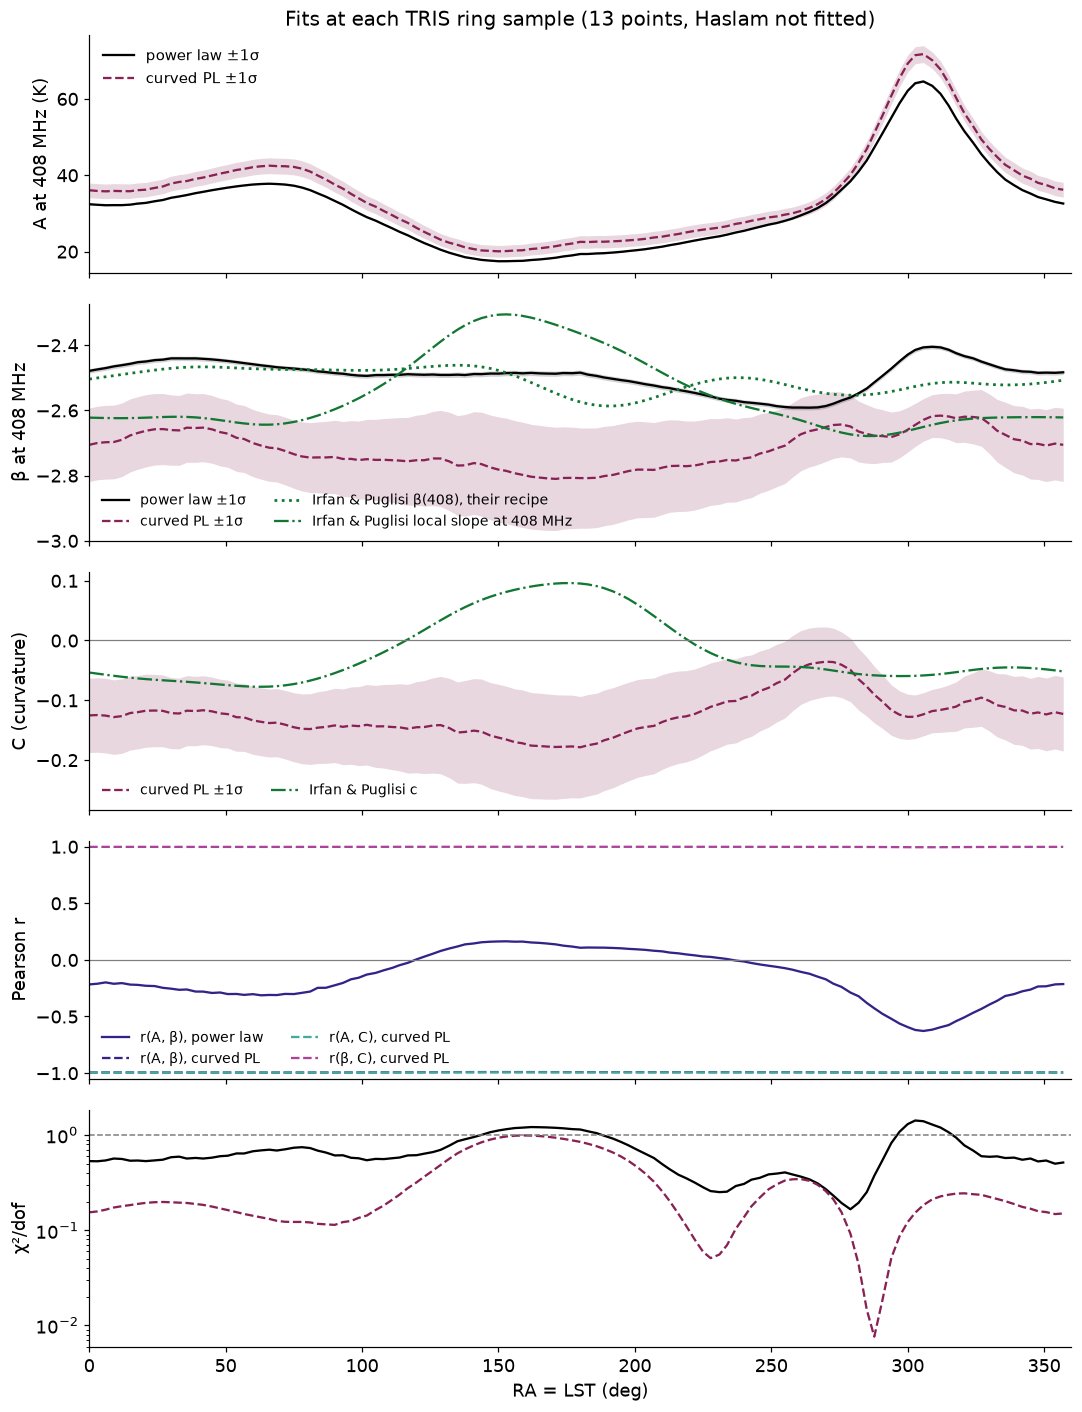

,model,median A_K,median beta,median χ²,mean χ²,dof,median χ²/dof,mean χ²/dof,median C
0,power law,32.150,-2.487,6.525,7.364,11,0.593,0.669,NaN
1,curved power law,35.546,-2.721,1.939,3.079,10,0.194,0.308,-0.126


,difference along the ring,median,min,max
0,power law β − Irfan β(408) recipe,0.019,-0.075,0.115
1,power law β − Irfan local slope 408,0.091,-0.181,0.244
2,curved PL β − Irfan local slope 408,-0.095,-0.488,0.027
3,curved PL C − Irfan c,-0.071,-0.274,0.014


In [ ]:
for m, F in FITS.items():
    df = pd.DataFrame({"sample": np.arange(N_SAMP), "ra_deg": RA})
    for j, n in enumerate(PARAMS[m]):
        df[n] = F["p"][:, j]; df["sigma_" + n] = np.sqrt(F["cov"][:, j, j])
    for a in range(len(PARAMS[m])):
        for b in range(a + 1, len(PARAMS[m])):
            df[f"corr_{PARAMS[m][a]}_{PARAMS[m][b]}"] = F["cov"][:, a, b] / np.sqrt(F["cov"][:, a, a] * F["cov"][:, b, b])
    df["chi2"], df["n_points"], df["dof"], df["chi2_per_dof"] = F["chi2"], F["n"], F["dof"], F["chi2"] / F["dof"]
    df.to_csv(OUT_DIR / f"fit_per_sample_{slug(m)}.csv", index=False)

panels = [("A_K", "A at 408 MHz (K)"), ("beta", "β at 408 MHz"), ("C", "C (curvature)"),
          ("corr", "Pearson r"), ("chi2dof", "χ²/dof")]
PAIR_COL = {("A_K", "beta"): "#332288", ("A_K", "C"): "#44AA99", ("beta", "C"): "#AA4499"}
PAIR_LABEL = {"A_K": "A", "beta": "β", "C": "C"}
fig, ax = plt.subplots(len(panels), 1, figsize=(10, 13), sharex=True)
for m, F in FITS.items():
    for a, (key, label) in zip(ax, panels):
        if key == "chi2dof":
            a.plot(RA, F["chi2"] / F["dof"], color=MCOL[m], ls=MLS[m], label=SHORT[m])
        elif key == "corr":
            for (p1, p2), col in PAIR_COL.items():
                if p1 in PARAMS[m] and p2 in PARAMS[m]:
                    i1, i2 = PARAMS[m].index(p1), PARAMS[m].index(p2)
                    r = F["cov"][:, i1, i2] / np.sqrt(F["cov"][:, i1, i1] * F["cov"][:, i2, i2])
                    a.plot(RA, r, color=col, ls=MLS[m],
                           label=f"r({PAIR_LABEL[p1]}, {PAIR_LABEL[p2]}), {SHORT[m]}")
        elif key in PARAMS[m]:
            j = PARAMS[m].index(key); v = F["p"][:, j]; e = np.sqrt(F["cov"][:, j, j])
            a.fill_between(RA, v - e, v + e, color=MCOL[m], alpha=0.18, lw=0)
            a.plot(RA, v, color=MCOL[m], ls=MLS[m], label=SHORT[m] + " ±1σ")
        a.set_ylabel(label)
IRFAN_COL = "#117733"
ax[1].plot(RA, IRFAN["beta408_recipe"], color=IRFAN_COL, ls=":", lw=1.8, label="Irfan & Puglisi β(408), their recipe")
ax[1].plot(RA, IRFAN["slope408"], color=IRFAN_COL, ls="-.", label="Irfan & Puglisi local slope at 408 MHz")
ax[2].plot(RA, IRFAN["c"], color=IRFAN_COL, ls="-.", label="Irfan & Puglisi c")
ax[1].legend(fontsize=9, ncol=2, loc="lower left")
ax[2].legend(fontsize=9, ncol=2, loc="lower left")
ax[2].axhline(0, color=HASLAM_COL)
ax[3].axhline(0, color=HASLAM_COL); ax[3].set_ylim(-1.05, 1.05)
ax[3].legend(fontsize=9, ncol=2, loc="lower left")
ax[4].axhline(1, color=HASLAM_COL, ls="--"); ax[4].set_yscale("log")
ax[0].legend(fontsize=10)
ax[-1].set_xlabel("RA = LST (deg)"); ax[-1].set_xlim(0, 360)
ax[0].set_title(f"Fits at each TRIS ring sample ({len(KEYS)} points, Haslam not fitted)")
fig.tight_layout(); fig.savefig(OUT_DIR / "test1_fit_parameters.png"); plt.show()

display(pd.DataFrame([{"model": m, **{f"median {n}": np.median(F["p"][:, j]) for j, n in enumerate(PARAMS[m])},
               "median χ²": np.median(F["chi2"]), "mean χ²": np.mean(F["chi2"]), "dof": int(F["dof"][0]),
               "median χ²/dof": np.median(F["chi2"] / F["dof"]), "mean χ²/dof": np.mean(F["chi2"] / F["dof"])}
              for m, F in FITS.items()]).round(3))
cmp = [("power law β − Irfan β(408) recipe", FITS.get("power law"), 1, IRFAN["beta408_recipe"]),
       ("power law β − Irfan local slope 408", FITS.get("power law"), 1, IRFAN["slope408"]),
       ("curved PL β − Irfan local slope 408", FITS.get("curved power law"), 1, IRFAN["slope408"]),
       ("curved PL C − Irfan c", FITS.get("curved power law"), 2, IRFAN["c"])]
display(pd.DataFrame([{"difference along the ring": n, "median": np.median(F["p"][:, j] - ir),
                       "min": np.min(F["p"][:, j] - ir), "max": np.max(F["p"][:, j] - ir)}
                      for n, F, j, ir in cmp if F is not None]).round(3))

### Test 2 — Models vs TRIS, residuals in kelvin
Top: the TRIS ring data (±1σ published error, shaded) and each fitted model at the TRIS effective frequency.
Bottom: residual = data − model, in K, for each model, with the TRIS 1σ error shaded. TRIS is **in** the fits, so this
shows how well each model goes through it, not a prediction.

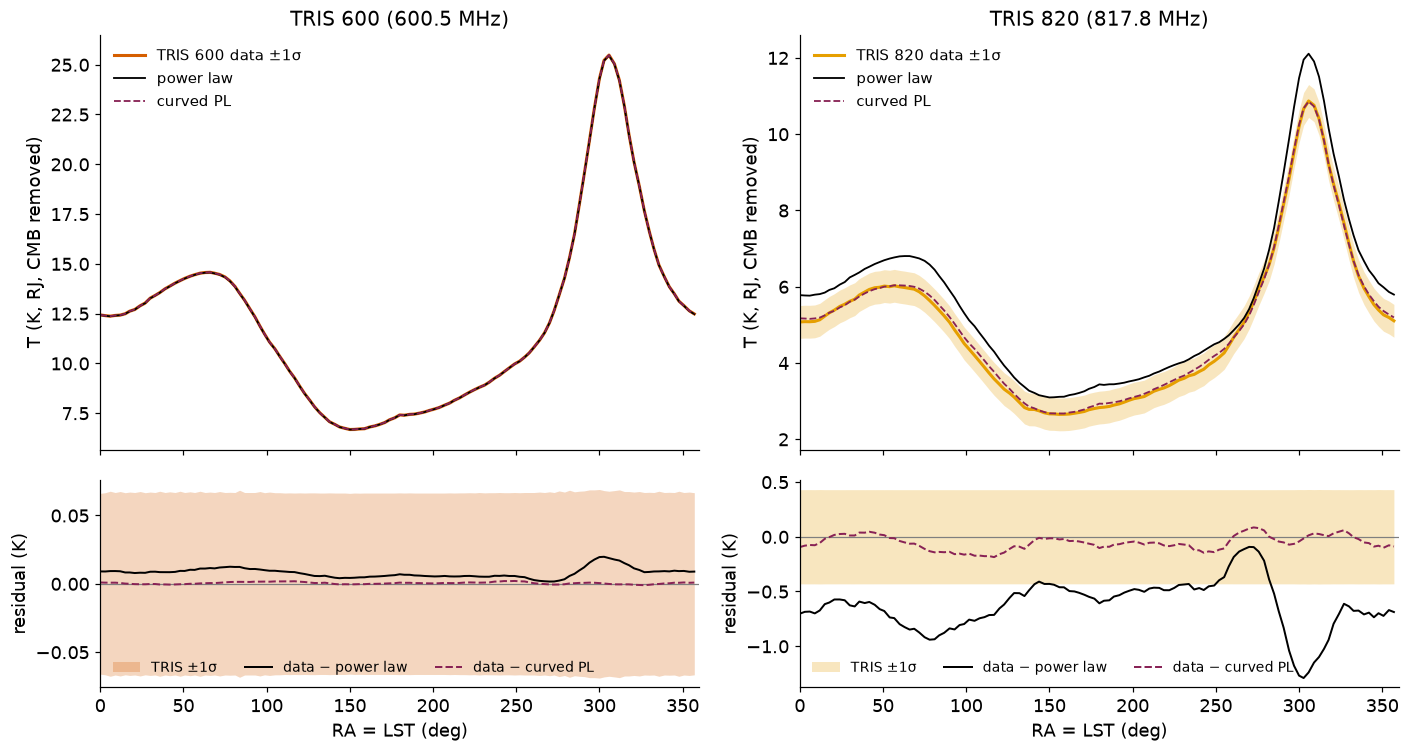

,data set,model,median residual (K),mean residual (K),rms residual (K),max |residual| (K),median σ (K)
0,TRIS 600,power law,0.008,0.008,0.009,0.020,0.067
1,TRIS 600,curved power law,0.000,0.000,0.001,0.002,0.067
2,TRIS 820,power law,-0.607,-0.625,0.666,1.291,0.430
3,TRIS 820,curved power law,-0.057,-0.054,0.084,0.186,0.430


In [ ]:
tris_keys = [k for k in KEYS if k.startswith("TRIS_")]
fig, ax = plt.subplots(2, len(tris_keys), figsize=(6.5 * len(tris_keys), 7), sharex=True,
                       gridspec_kw={"height_ratios": [2, 1]}, squeeze=False)
rows = []
for j, k in enumerate(tris_keys):
    d, s = T_DATA[k], S_DATA[k]
    a, r = ax[0, j], ax[1, j]
    a.fill_between(RA, d - s, d + s, color=COL[k], alpha=0.25, lw=0)
    a.plot(RA, d, color=COL[k], lw=2, label=f"{NAMES[k]} data ±1σ")
    r.fill_between(RA, -s, s, color=COL[k], alpha=0.25, lw=0, label="TRIS ±1σ")
    r.axhline(0, color=HASLAM_COL)
    for m in FIT_MODELS:
        (mod,), _ = predict_tod([NU[k]], m)
        a.plot(RA, mod, color=MCOL[m], ls=MLS[m], label=SHORT[m])
        res = d - mod
        r.plot(RA, res, color=MCOL[m], ls=MLS[m], label=f"data − {SHORT[m]}")
        rows.append({"data set": NAMES[k], "model": m, "median residual (K)": np.nanmedian(res),
                     "mean residual (K)": np.nanmean(res), "rms residual (K)": np.sqrt(np.nanmean(res ** 2)),
                     "max |residual| (K)": np.nanmax(np.abs(res)), "median σ (K)": np.nanmedian(s)})
    a.set_title(f"{NAMES[k]} ({NU[k]:g} MHz)"); a.set_ylabel("T (K, RJ, CMB removed)"); a.legend(fontsize=10)
    r.set_ylabel("residual (K)"); r.set_xlabel("RA = LST (deg)"); r.set_xlim(0, 360)
    r.legend(fontsize=9, loc="lower left", ncol=3)
fig.tight_layout(); fig.savefig(OUT_DIR / "test2_tris_residuals_K.png"); plt.show()
pd.DataFrame(rows).round(3)

### Test 3 — χ² of the fit at every frequency, and residuals in K
For each data set, its own χ² contribution χ²_i = ((T_i − model_i)/σ_i)² along the ring (one panel per model), then the
residual data − model in K for every data set, with the data set's ±1σ shaded. The total χ² per sample is the sum over
the data sets. The samples are correlated (the TRIS beam is ~20° wide and the ring is sampled every 3°), so the medians and means
below are descriptive, not independent tests.

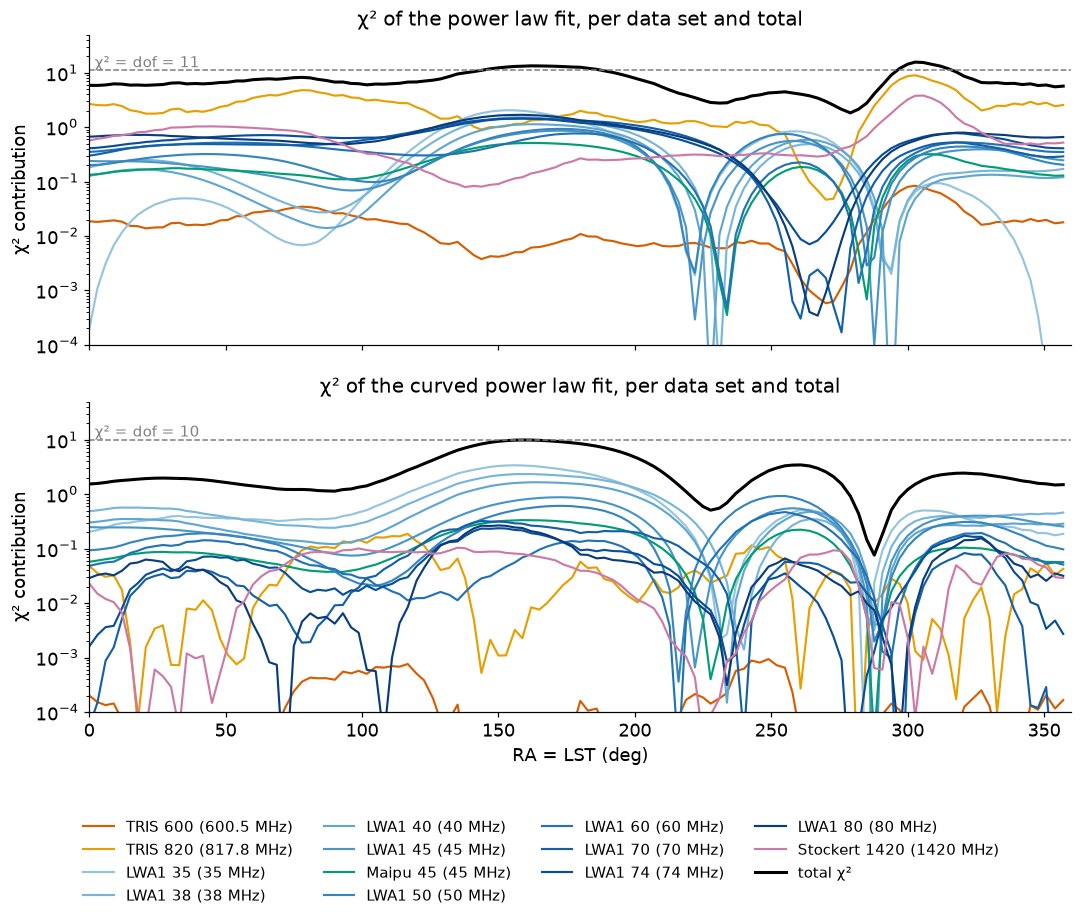

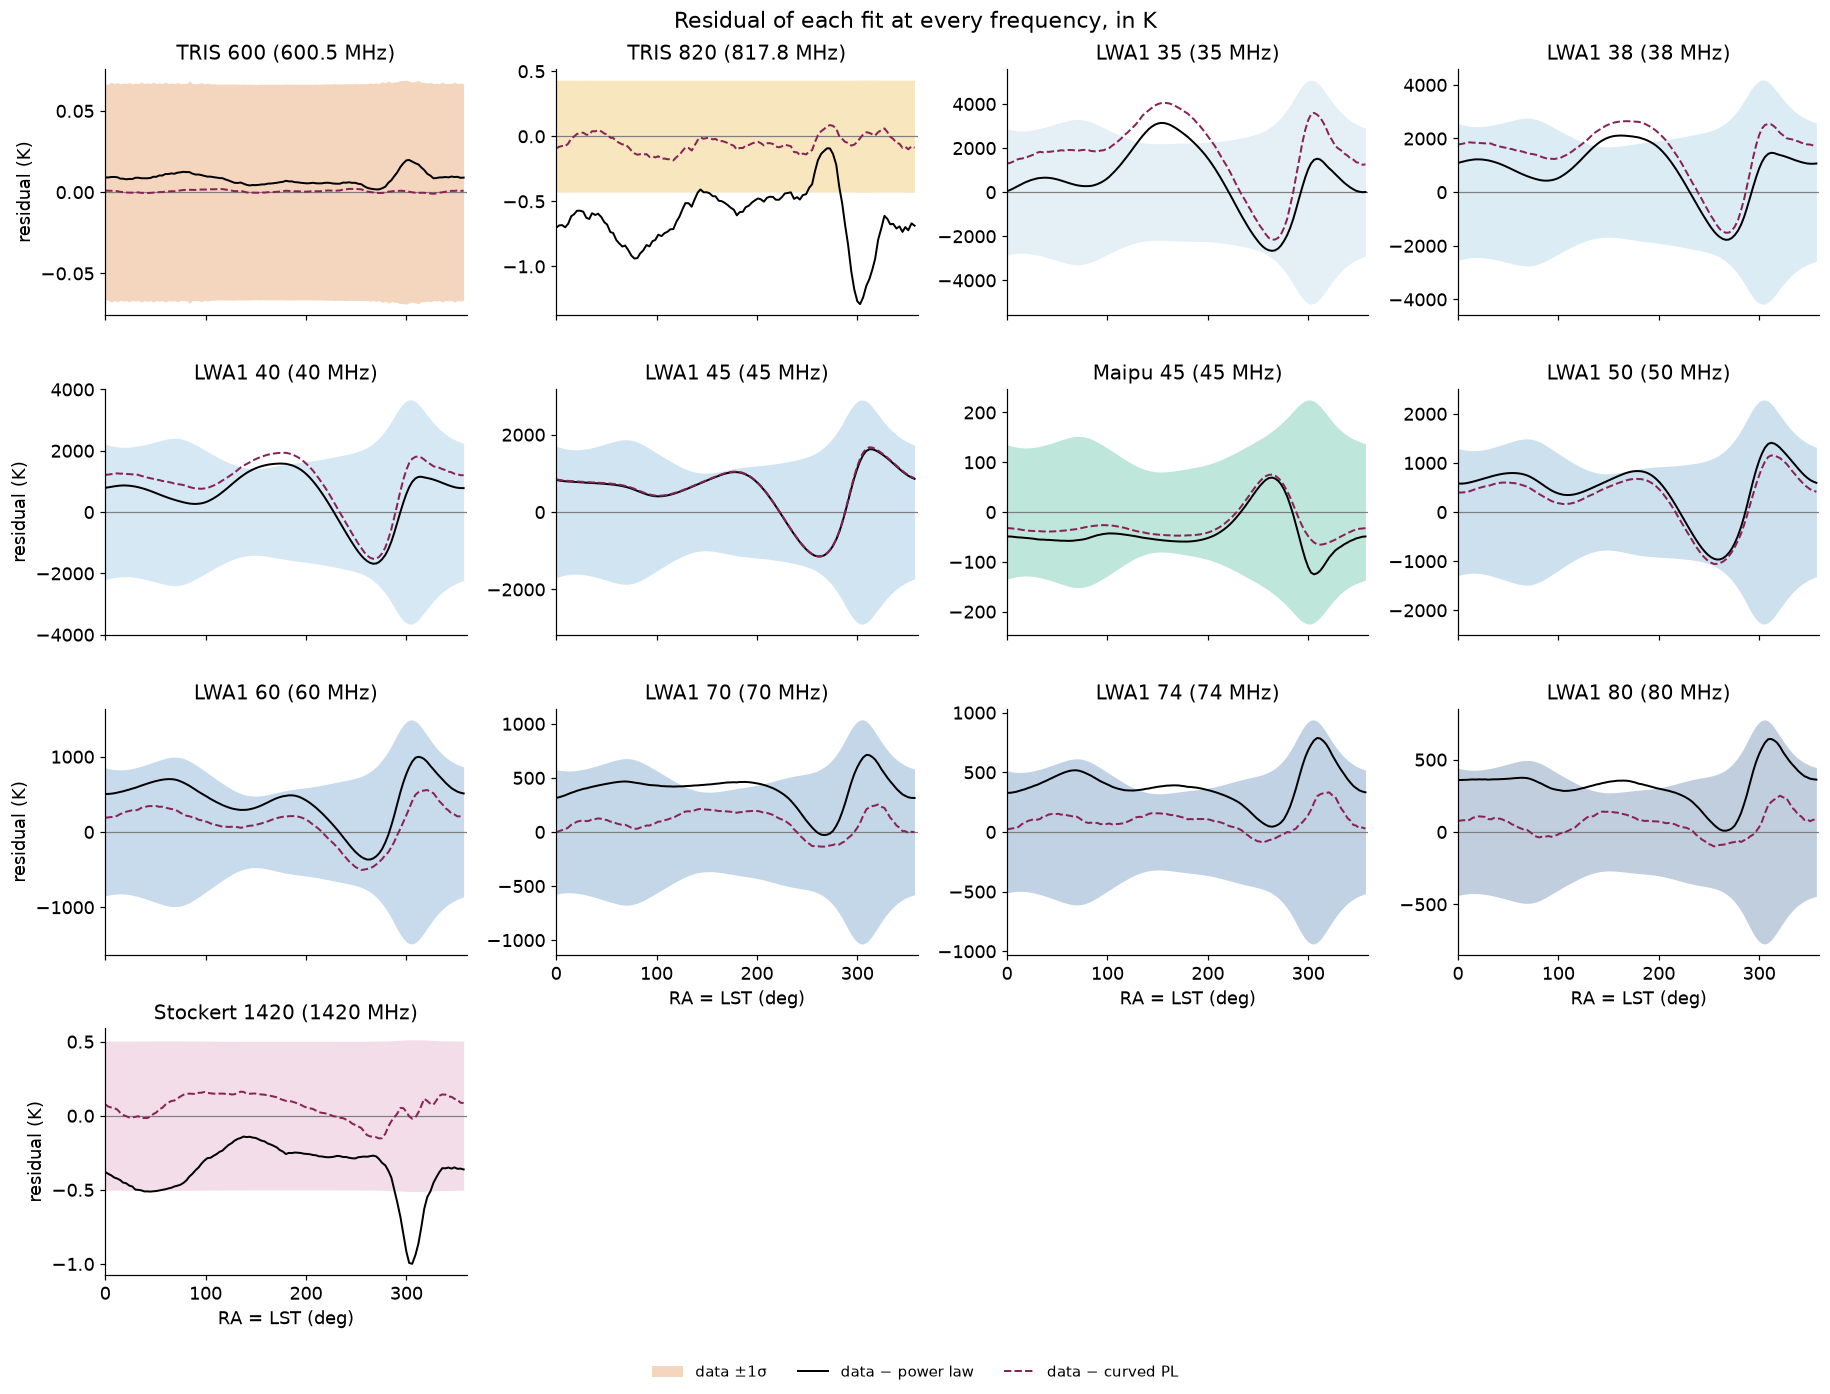

,model,data set,frequency (MHz),median χ²_i,mean χ²_i,max χ²_i,samples with χ²_i > 4,median residual (K),median σ (K)
0,power law,TRIS 600,600.5,0.015,0.018,0.084,0.0,0.008,0.067
1,power law,TRIS 820,817.8,1.991,2.394,8.978,15.0,-0.607,0.430
2,power law,LWA1 35,35.0,0.076,0.416,2.044,0.0,559.391,2820.455
3,power law,LWA1 38,38.0,0.184,0.386,1.522,0.0,1088.568,2450.681
4,power law,LWA1 40,40.0,0.133,0.303,1.131,0.0,781.048,2120.079
5,power law,LWA1 45,45.0,0.236,0.302,0.860,0.0,713.259,1611.933
6,power law,Maipu 45,45.0,0.164,0.204,0.513,0.0,-52.441,133.330
7,power law,LWA1 50,50.0,0.295,0.354,0.929,0.0,614.948,1250.206
8,power law,LWA1 60,60.0,0.391,0.374,0.766,0.0,476.017,827.827
9,power law,LWA1 70,70.0,0.482,0.598,1.443,0.0,426.966,568.797


In [ ]:
RES_K, CHI2_I = {}, {}
for m in FIT_MODELS:
    for k in KEYS:
        (mod,), _ = predict_tod([NU[k]], m)
        RES_K[m, k] = T_DATA[k] - mod
        CHI2_I[m, k] = (RES_K[m, k] / S_DATA[k]) ** 2

fig, ax = plt.subplots(len(FIT_MODELS), 1, figsize=(10, 4.2 * len(FIT_MODELS)), sharex=True, sharey=True, squeeze=False)
for a, m in zip(ax[:, 0], FIT_MODELS):
    F = FITS[m]
    for k in KEYS:
        a.plot(RA, CHI2_I[m, k], color=COL[k], label=f"{NAMES[k]} ({NU[k]:g} MHz)")
    a.plot(RA, F["chi2"], color=COLORS["ink"], lw=2, label="total χ²")
    a.axhline(F["dof"][0], color=HASLAM_COL, ls="--")
    a.text(2, F["dof"][0] * 1.15, f"χ² = dof = {F['dof'][0]}", color=HASLAM_COL, fontsize=10)
    a.set_yscale("log"); a.set_ylim(1e-4, 50); a.set_ylabel("χ² contribution")
    a.set_title(f"χ² of the {m} fit, per data set and total")
ax[-1, 0].set_xlabel("RA = LST (deg)"); ax[-1, 0].set_xlim(0, 360)
h_, l_ = ax[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=4, fontsize=10)
fig.tight_layout(rect=(0, 0.035 * int(np.ceil((len(KEYS) + 1) / 4)), 1, 1)); fig.savefig(OUT_DIR / "test3_chi2_per_frequency.png"); plt.show()

# residuals in K, one panel per data set (their scales differ by four orders of magnitude), both models in each
NCOL = 4
NROW = int(np.ceil(len(KEYS) / NCOL))
fig, ax = plt.subplots(NROW, NCOL, figsize=(4.2 * NCOL, 3.2 * NROW), sharex=True, squeeze=False)
for a in ax.ravel()[len(KEYS):]:
    a.set_visible(False)
for a, k in zip(ax.ravel(), KEYS):
    a.fill_between(RA, -S_DATA[k], S_DATA[k], color=COL[k], alpha=0.25, lw=0, label="data ±1σ")
    a.axhline(0, color=HASLAM_COL)
    for m in FIT_MODELS:
        a.plot(RA, RES_K[m, k], color=MCOL[m], ls=MLS[m], label=f"data − {SHORT[m]}")
    a.set_title(f"{NAMES[k]} ({NU[k]:g} MHz)"); a.set_xlim(0, 360)
for a in ax[:, 0]:
    a.set_ylabel("residual (K)")
for j, a in enumerate(ax.ravel()[:len(KEYS)]):
    if j + NCOL >= len(KEYS):                     # the lowest visible panel in its column
        a.set_xlabel("RA = LST (deg)"); a.tick_params(labelbottom=True)
h_, l_ = ax[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=3, fontsize=10)
fig.suptitle("Residual of each fit at every frequency, in K")
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(OUT_DIR / "test3_residuals_K_all_frequencies.png"); plt.show()

rows = []
for m in FIT_MODELS:
    F = FITS[m]
    for k in KEYS:
        rows.append({"model": m, "data set": NAMES[k], "frequency (MHz)": NU[k],
                     "median χ²_i": np.nanmedian(CHI2_I[m, k]), "mean χ²_i": np.nanmean(CHI2_I[m, k]),
                     "max χ²_i": np.nanmax(CHI2_I[m, k]), "samples with χ²_i > 4": int(np.sum(CHI2_I[m, k] > 4)),
                     "median residual (K)": np.nanmedian(RES_K[m, k]), "median σ (K)": np.nanmedian(S_DATA[k])})
    rows.append({"model": m, "data set": f"total (dof {F['dof'][0]})", "frequency (MHz)": np.nan,
                 "median χ²_i": np.median(F["chi2"]), "mean χ²_i": np.mean(F["chi2"]), "max χ²_i": np.max(F["chi2"]),
                 "samples with χ²_i > 4": np.nan})
chi2_tab = pd.DataFrame(rows)
chi2_tab.to_csv(OUT_DIR / "test3_chi2_per_frequency.csv", index=False)
per_sample = {"ra_deg": RA}
for m in FIT_MODELS:
    per_sample[f"chi2_total {SHORT[m]}"] = FITS[m]["chi2"]
    for k in KEYS:
        per_sample[f"chi2 {NAMES[k]} {SHORT[m]}"] = CHI2_I[m, k]
        per_sample[f"residual_K {NAMES[k]} {SHORT[m]}"] = RES_K[m, k]
pd.DataFrame(per_sample).to_csv(OUT_DIR / "test3_chi2_per_sample.csv", index=False)
chi2_tab.round(3)

### Test 4 — Held-out check at 408 MHz (Haslam)
Haslam is not in the fits, so this is a true prediction: each model's predicted ring TOD at 408 MHz against Haslam's
beam-matched ring TOD (both RJ, CMB removed). Residual = Haslam − prediction, in K, with Haslam's published 1σ (10%
scale ⊕ 3 K zero level) shaded. Haslam's own calibration is what this project questions, so a residual here is not
necessarily a failure of a fit.

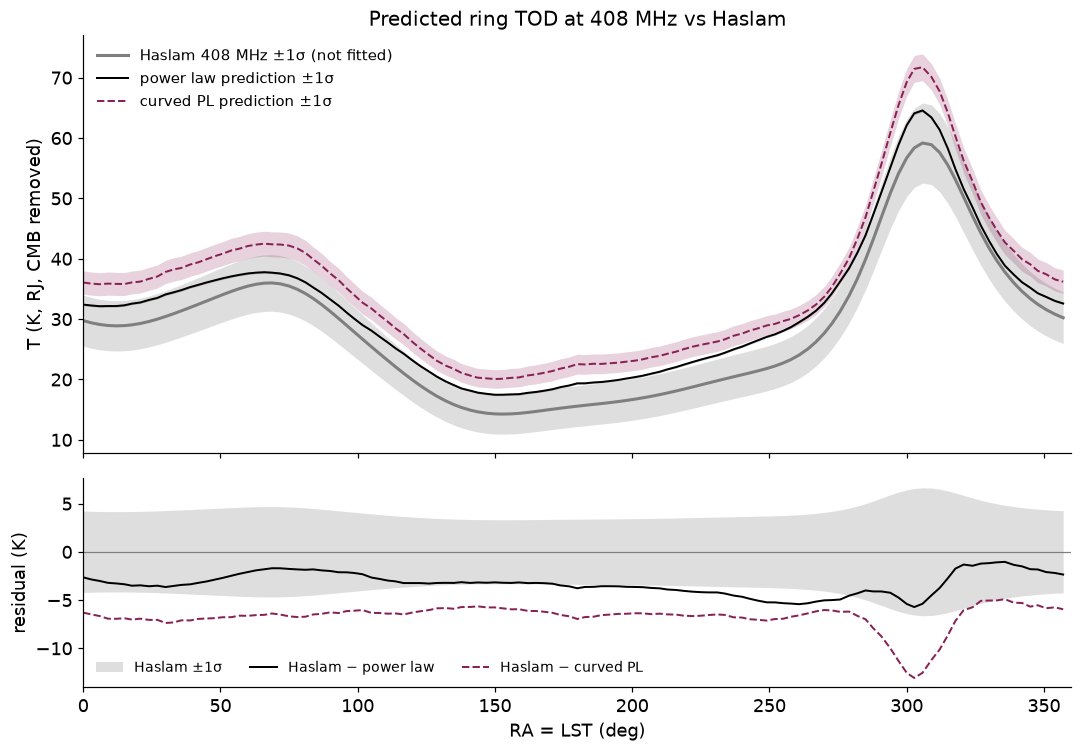

,model,median Haslam − prediction (K),mean (K),rms (K),median σ prediction (K),median σ Haslam (K)
0,power law,-3.252,-3.307,3.494,0.170,4.167
1,curved power law,-6.506,-6.747,6.883,1.892,4.167


In [ ]:
h, hs = HASLAM["T"], HASLAM["S"]
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].fill_between(RA, h - hs, h + hs, color=HASLAM_COL, alpha=0.25, lw=0)
ax[0].plot(RA, h, color=HASLAM_COL, lw=2, label="Haslam 408 MHz ±1σ (not fitted)")
ax[1].fill_between(RA, -hs, hs, color=HASLAM_COL, alpha=0.25, lw=0, label="Haslam ±1σ")
ax[1].axhline(0, color=HASLAM_COL)
rows = []
for m in FIT_MODELS:
    (p408,), (s408,) = predict_tod([HASLAM["nu"]], m)
    ax[0].fill_between(RA, p408 - s408, p408 + s408, color=MCOL[m], alpha=0.2, lw=0)
    ax[0].plot(RA, p408, color=MCOL[m], ls=MLS[m], label=f"{SHORT[m]} prediction ±1σ")
    ax[1].plot(RA, h - p408, color=MCOL[m], ls=MLS[m], label=f"Haslam − {SHORT[m]}")
    r = h - p408
    rows.append({"model": m, "median Haslam − prediction (K)": np.nanmedian(r), "mean (K)": np.nanmean(r),
                 "rms (K)": np.sqrt(np.nanmean(r ** 2)), "median σ prediction (K)": np.nanmedian(s408),
                 "median σ Haslam (K)": np.nanmedian(hs)})
ax[0].set_ylabel("T (K, RJ, CMB removed)"); ax[0].legend(fontsize=10)
ax[0].set_title("Predicted ring TOD at 408 MHz vs Haslam")
ax[1].set_ylabel("residual (K)"); ax[1].set_xlabel("RA = LST (deg)"); ax[1].set_xlim(0, 360)
ax[1].legend(fontsize=9, ncol=3)
fig.tight_layout(); fig.savefig(OUT_DIR / "test4_haslam_408_heldout.png"); plt.show()
pd.DataFrame(rows).round(3)

### Test 5 — Predicted ring TODs at other frequencies
Top row: each model's ring TOD at every frequency in `PRED_FREQS_MHZ` (1σ bands are drawn but are ~1% of T, so thin on
a log axis). Bottom left: the full spectrum at a few ring samples with the fitted points (and Haslam, not fitted).
Bottom right: the difference between the two models' predictions, curved PL − power law, in K, against frequency, with
each sample's 1σ of the first model shaded; the y axis is linear within ±1 K and logarithmic beyond — where the choice of model matters for a prediction. Saved per model to
`paper_outputs/tod_prediction/predicted_tods_<model>.csv` (fit convention, CMB removed) and `predicted_tods_with_cmb_<model>.csv`.

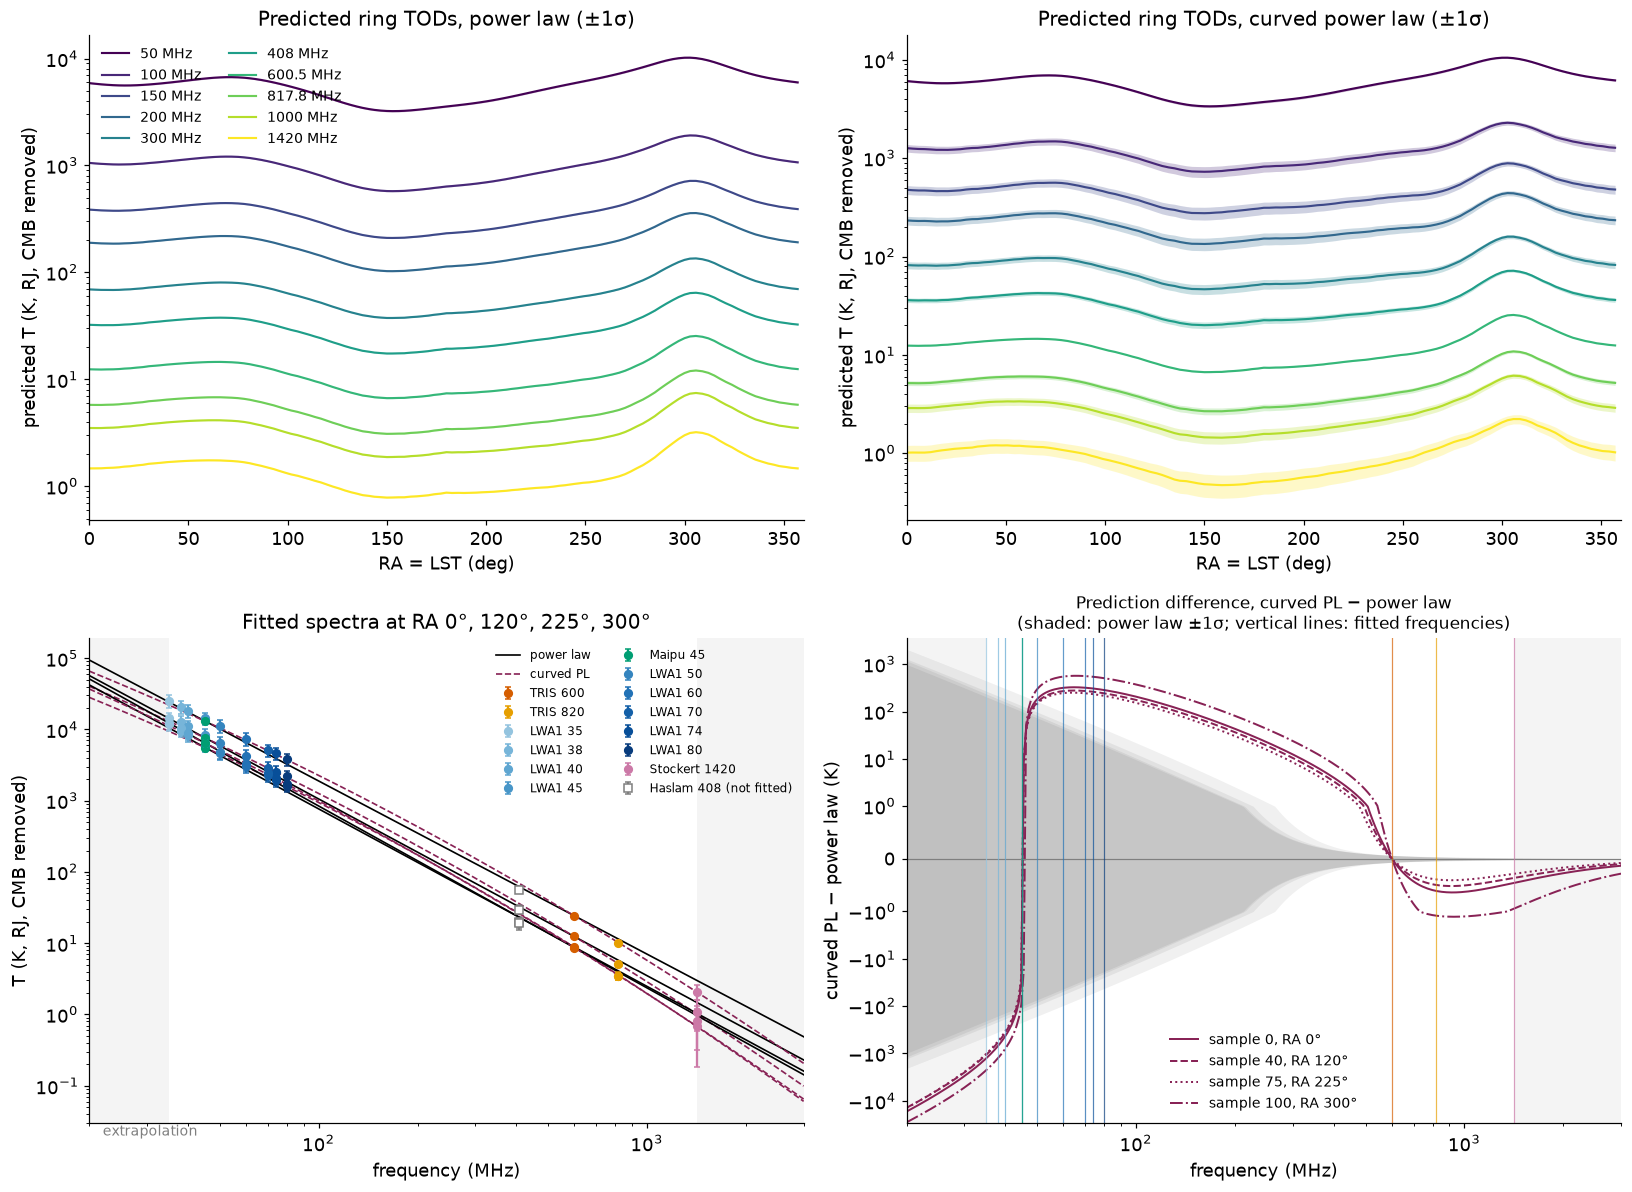

,frequency (MHz),median T power law (K),median σ power law (K),median T curved PL (K),median σ curved PL (K),median curved PL − power law (K)
0,50.0,5807.4060,95.8772,6001.2271,135.0093,167.4943
1,100.0,1042.8712,12.5371,1228.5734,107.9310,189.9842
2,150.0,381.7696,3.6515,462.3146,47.6012,83.4247
3,200.0,187.0041,1.4887,227.6008,22.8938,40.3214
4,300.0,68.6858,0.4182,80.6010,6.5545,11.7562
5,408.0,32.1498,0.1696,35.5457,1.8917,3.4741
6,600.5,12.3434,0.0665,12.3522,0.0666,0.0076
7,817.8,5.7064,0.0363,5.1603,0.2828,-0.5815
8,1000.0,3.4281,0.0250,2.8803,0.2799,-0.5971
9,1420.0,1.4190,0.0130,1.0168,0.1859,-0.4268


In [ ]:
PRED = {}
for m in FIT_MODELS:
    Tp, Sp = predict_tod(PRED_FREQS_MHZ, m)
    Tc, _ = predict_tod(PRED_FREQS_MHZ, m, include_cmb=True)
    PRED[m] = (Tp, Sp)
    for T_, name in ((Tp, "predicted_tods"), (Tc, "predicted_tods_with_cmb")):
        out = {"sample": np.arange(N_SAMP), "ra_deg": RA}
        for f, t, s in zip(PRED_FREQS_MHZ, T_, Sp):
            out[f"T_K_{f:g}MHz"], out[f"sigma_K_{f:g}MHz"] = t, s
        pd.DataFrame(out).to_csv(OUT_DIR / f"{name}_{slug(m)}.csv", index=False)

cmap = plt.get_cmap("ring")
fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2)
for c, m in enumerate(FIT_MODELS[:2]):
    a = fig.add_subplot(gs[0, c])
    Tp, Sp = PRED[m]
    for i, (f, t, s) in enumerate(zip(PRED_FREQS_MHZ, Tp, Sp)):
        col = cmap(i / max(len(PRED_FREQS_MHZ) - 1, 1))
        a.fill_between(RA, t - s, t + s, color=col, alpha=0.25, lw=0)
        a.plot(RA, t, color=col, label=f"{f:g} MHz")
    a.set_yscale("log"); a.set_xlim(0, 360); a.set_xlabel("RA = LST (deg)")
    a.set_ylabel("predicted T (K, RJ, CMB removed)"); a.set_title(f"Predicted ring TODs, {m} (±1σ)")
    if c == 0:
        a.legend(fontsize=9, ncol=2, loc="upper left")

nu_grid = np.geomspace(20, 3000, 300)
a = fig.add_subplot(gs[1, 0])
G = {m: predict_tod(nu_grid, m) for m in FIT_MODELS}
for j, i in enumerate(SPECTRUM_SAMPLES):
    for m in FIT_MODELS:
        a.plot(nu_grid, G[m][0][:, i], color=MCOL[m], ls=MLS[m],
               label=SHORT[m] if j == 0 else None)
    for k in KEYS:
        a.errorbar(NU[k], T_DATA[k][i], yerr=S_DATA[k][i], fmt="o", ms=5, color=COL[k], capsize=2,
                   label=NAMES[k] if j == 0 else None)
    a.errorbar(HASLAM["nu"], HASLAM["T"][i], yerr=HASLAM["S"][i], fmt="s", ms=5, mfc="white",
               color=HASLAM_COL, capsize=2, label="Haslam 408 (not fitted)" if j == 0 else None)
lo, hi = min(NU.values()), max(NU.values())
a.axvspan(20, lo, color=HASLAM_COL, alpha=0.08, lw=0); a.axvspan(hi, 3000, color=HASLAM_COL, alpha=0.08, lw=0)
a.text(22, 0.02, "extrapolation", fontsize=9, color=HASLAM_COL)
a.set_xscale("log"); a.set_yscale("log"); a.set_xlim(20, 3000)
a.set_xlabel("frequency (MHz)"); a.set_ylabel("T (K, RJ, CMB removed)")
a.set_title("Fitted spectra at RA " + ", ".join(f"{RA[i]:.0f}°" for i in SPECTRUM_SAMPLES)); a.legend(fontsize=8, ncol=2)

if len(FIT_MODELS) >= 2:
    m0, m1 = FIT_MODELS[0], FIT_MODELS[1]
    a = fig.add_subplot(gs[1, 1])
    ls = ["-", "--", ":", "-."]
    for j, i in enumerate(SPECTRUM_SAMPLES):
        a.fill_between(nu_grid, -G[m0][1][:, i], G[m0][1][:, i], color=MCOL[m0], alpha=0.06, lw=0)
        a.plot(nu_grid, G[m1][0][:, i] - G[m0][0][:, i], color=MCOL[m1], ls=ls[j % 4],
               label=f"sample {i}, RA {RA[i]:.0f}°")
    a.axhline(0, color=HASLAM_COL)
    a.axvspan(20, lo, color=HASLAM_COL, alpha=0.08, lw=0); a.axvspan(hi, 3000, color=HASLAM_COL, alpha=0.08, lw=0)
    for k in KEYS:
        a.axvline(NU[k], color=COL[k], alpha=0.7)
    a.set_xscale("log"); a.set_yscale("symlog", linthresh=1.0); a.set_xlim(20, 3000)
    a.set_xlabel("frequency (MHz)"); a.set_ylabel(f"{SHORT[m1]} − {SHORT[m0]} (K)")
    a.set_title(f"Prediction difference, {SHORT[m1]} − {SHORT[m0]}\n(shaded: {SHORT[m0]} ±1σ; vertical lines: fitted frequencies)", fontsize=11)
    a.legend(fontsize=9)
fig.tight_layout(); fig.savefig(OUT_DIR / "test5_predicted_tods.png"); plt.show()

rows = []
for i, f in enumerate(PRED_FREQS_MHZ):
    row = {"frequency (MHz)": f}
    for m in FIT_MODELS:
        Tp, Sp = PRED[m]
        row[f"median T {SHORT[m]} (K)"] = np.median(Tp[i]); row[f"median σ {SHORT[m]} (K)"] = np.median(Sp[i])
    if len(FIT_MODELS) >= 2:
        row[f"median {SHORT[FIT_MODELS[1]]} − {SHORT[FIT_MODELS[0]]} (K)"] = np.median(PRED[FIT_MODELS[1]][0][i] - PRED[FIT_MODELS[0]][0][i])
    rows.append(row)
pd.DataFrame(rows).round(4)

### Test 6 — moved to the pipeline (step 7)

The RHINO prediction (60–80 MHz, through the TRIS beam, deconvolved with a GSM2016 prior and observed with the RHINO
beam at Jodrell Bank, against the sky models) is pipeline step 7: `python run_pipeline.py --step rhino`
(code in `moonrunes.pipeline.step_rhino`, settings in `configs/run_pipeline.yaml` → `pipeline.rhino`). It is fed by
**our spectral model** (step 5: the model chosen in step 4, fitted with UltraNest to every allowed data set,
TRIS included) rather than this Part's 13-point weighted-least-squares fit, so its numbers differ from this Part's
older Test 6 results (`test_outputs/tod_prediction/test6_*`, 2026-11-05). The pipeline writes
`paper_outputs/pipeline/step7_rhino/`; the older Test 6 cells are archived in
`../moonrunes_archive_2026-11-16/notebooks/test_results.ipynb.before_pipeline`.

### Using the prediction
```python
T, sigma = predict_tod([150.0, 350.0], "power law")                   # (2, 120): RJ K, CMB removed, ±1σ
T, sigma = predict_tod([150.0], "curved power law", include_cmb=True) # + T_CMB,RJ(150 MHz), as in the TRIS ring data
fit_other = fit_ring("power law", keys=["TRIS_600", "TRIS_820", "LWA_80MHz.fits", "STOCKERT_VILLA_1400MHZ.fits"])
T, sigma = predict_tod([150.0], "power law", fit=fit_other)           # a fit with fewer data sets (each must be in DATASETS)
```
Column j of `T` and `sigma` is ring sample j; its RA = LST (deg) is `RA[j]`. "samples with χ²_i > 4" is left empty for
the totals.

In [ ]:
# Total notebook run time: from the first code cell (which sets _NB_T0) to here.
import time as _nb_time
if "_NB_T0" in globals():
    _dt = _nb_time.time() - _NB_T0
    print(f"total notebook run time: {_dt:.0f} s ({int(_dt // 3600)}h {int(_dt % 3600 // 60):02d}m {int(_dt % 60):02d}s)")
else:
    print("total notebook run time: not recorded (the first code cell was not run)")